### 이진 분류
: banknote authentification dataset : 진짜 지폐와 가짜 지폐를 판별

- 데이터 : 1372개의 instance
- 정답(variance): 0-> 진짜, 1 -> 가짜를 의미
- 특징(입력특징): 4개의 특징
    - variance(분산): 이미지를 wavelit변환해서 얻은 값들이 퍼져있는 정도
    - skewness(왜도): 비대칭성
    - curtosis(첨도): 극단성
    - entropy(엔트로피): 불확실성(밝기)
        - 낮으면 특정 값이나 패턴에 집중되어 있음(불확실성 낮음)
        - 높다면 다양한 값이 나타나고 분포가 복잡해지는 경향(불확실성 높음)

- 4개의 특징에 대한 입력값으로 위조지폐를 찾아내는 모델을 개발

In [18]:
import pandas as  pd
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import *
from sklearn.preprocessing import StandardScaler, MinMaxScaler

import random

#### Step 1. 데이터 불러오기 및 전처리

In [19]:
# # 사이트에서 직접 다운로드
# url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt'
# df = pd.read_csv(url,names=columns)

# 파일 다운로드 해서 불러오기
columns = ['variance', 'skewness', 'curtosis', 'entropy', 'class']
df = pd.read_csv('data_banknote_authentication.txt', names= columns)
print(df.head())
print('데이터의 크기:', df.shape)                 # 1372개의 instance
print('클래스별 개수:')
print(df['class'].value_counts().sort_index())  # 가짜: 610, 진짜: 762

   variance  skewness  curtosis  entropy  class
0   3.62160    8.6661   -2.8073 -0.44699      0
1   4.54590    8.1674   -2.4586 -1.46210      0
2   3.86600   -2.6383    1.9242  0.10645      0
3   3.45660    9.5228   -4.0112 -3.59440      0
4   0.32924   -4.4552    4.5718 -0.98880      0
데이터의 크기: (1372, 5)
클래스별 개수:
class
0    762
1    610
Name: count, dtype: int64


In [20]:
# Input, Target 데이터 분리
# target = 'class'
# x = df.drop(target, axis = 1)
# y = df.loc[:, target]
x = torch.tensor(df[['variance','skewness','curtosis','entropy']].values, dtype= torch.float32)
y = torch.tensor(df[['class']].values, dtype = torch.float32).reshape(-1,1)

# 데이터셋 생성
torch.manual_seed(42)   # 은하수를 여행하는 히치하이커를 위한 안내서
# x_train, x_val, y_train, y_val = train_test_split(x, y, test_size=0.3 ,randomseed=20)
train_indices = []
test_indices = []

# # train_test_split을 하드코딩
# for class_value in [0,1]:
#     class_indices = []

#     for i in range(len(y)):
#         if y[i].item() == class_value:
#             class_indices.append(i)

#     # 순서를 무작위로 섞기
#     random.shuffle(class_indices)

#     # 학습 80%, 테스트 20% 분리
#     split = int(len(class_indices) * 0.8)

#     # extend() : list에 다른 리스트의 요소를 집어넣는 메소드
#     train_indices.extend(class_indices[:split])
#     test_indices.extend(class_indices[split:])

# print(len(test_indices))
# print(len(train_indices))

# 함수
for class_value in [0,1] :
    # where() : 조건을 만족하는 데이터 찾기. 결과는 튜플로 반환
    class_indices = torch.where(y.squeeze() == class_value)[0]

    # randperm() : 0부터 지정한 숫자까지의 정수를 무작위로 섞어서 반환
    class_indices = class_indices[torch.randperm(len(class_indices))]

    # 데이터 나누기
    split = int(len(class_indices)* 0.8)

    train_indices.extend(class_indices[:split])
    test_indices.extend(class_indices[split:])

# print(len(test_indices))
# print(len(train_indices))

# 학습 테스트 데이터 섞어서 텐서로 만들기 (클래스0 앞쪽에, 클래스 1 뒤쪽에 몰려있음)
# 리스트 → 인덱스용 1차원 정수 텐서
train_indices = torch.tensor(train_indices, dtype=torch.long)
test_indices = torch.tensor(test_indices, dtype=torch.long)

# 순서 섞기
train_indices = train_indices[torch.randperm(len(train_indices))]
test_indices = test_indices[torch.randperm(len(test_indices))]

X_train = x[train_indices]  # X = (1097, 4)
X_test = x[test_indices]    # X = (275, 4)
y_train = y[train_indices]  # Y = (1097, 4)
y_test = y[test_indices]    # Y = (275, 4)

# 데이터 정규화 : 편차가 지나치게 튀는 값으로 인하여 학습이 오염되는 문제를 해결
# 정규화할 때 같은 특징을 가진 요소들끼리 정규화해야함 ( 전체를 정규화하거나 열방향 정규화 X)
mean = X_train.mean(dim=0)                      # 행의 방향 즉, 열의 평균
std = X_train.std(dim=0).clamp(min=1e-8)    
# 0으로 나누는 문제를 해결하기 위해 clam(min=1e-8)으로 최솟값을 0.00000008로 설정

x_train = (X_train - mean) / std
x_test = (X_test - mean) /std                   
# X_train의 mean와 std로 test도 정규화하는 이유: 동일한 기준으로 변환

print('x_train :', x_train.shape)
print('y_train :', y_train.shape)
print('x_test :', x_test.shape)
print('y_test :', y_test.shape)

x_train : torch.Size([1097, 4])
y_train : torch.Size([1097, 1])
x_test : torch.Size([275, 4])
y_test : torch.Size([275, 1])


In [27]:
# 데이터 로더 생성
BATCH_SIZE = 32

train_ds = TensorDataset(x_train, y_train)
test_ds = TensorDataset(x_test, y_test)

train_dl = DataLoader(train_ds, batch_size = BATCH_SIZE, shuffle= True)
test_dl = DataLoader(test_ds, batch_size = BATCH_SIZE, shuffle= False)

N = len(train_dl.dataset)
print(N)

1097


#### Step 2. 모델 만들기

In [28]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.linear = nn.Sequential(nn.Linear(4,100),
                                    nn.Sigmoid(),
                                    nn.Linear(100,1),
                                    nn.Sigmoid()
                                    )

    def forward(self, x):
        x = self.linear(x)
        return x

model = MLP()

#### Step 3. 모델 학습

In [29]:
# Train
LR = 1e-1
EPOCH = 100
# 선형회귀는 SGD 사용이 더 유리
optimizer = optim.SGD(model.parameters(), lr = LR)
criterion = nn.BCELoss()

loss_history = []

model.train()
for ep in range(EPOCH):
    
    # rloss : 기존에는 주기별 loss를 바로 볼 수 있었다면 
    # 현 모델에서는 배치별로 데이터를 나누었기 때문에 epoch의 평균 loss를 보고 싶다면
    # 배치의 평균 손실에 배치의 데이터 개수를 곱한 뒤, 누적시켜 학습의 경과를 기록
    # (배치 반복문이 끝난 뒤 전체 데이터 개수(N)로 나눠야 epoch의 평균 손실이 됩)
    rloss = 0

    for x_batch, y_batch in train_dl:
        # inference
        y_hat = model(x_batch)

        # loss
        loss = criterion(y_hat, y_batch)

        # update
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # rloss
        rloss += loss.item() * x_batch.shape[0]

    # rloss
    epoch_loss = rloss / N  # N = len(train_dl.dataset) = 1097
    # loss_history
    loss_history.append(epoch_loss)

    
    # print(f'Epoch: {ep+1}, loss: {epoch_loss:.4f}')
print(f'Epoch: {ep+1}, loss: {epoch_loss:.4f}')


Epoch: 100, loss: 0.0307


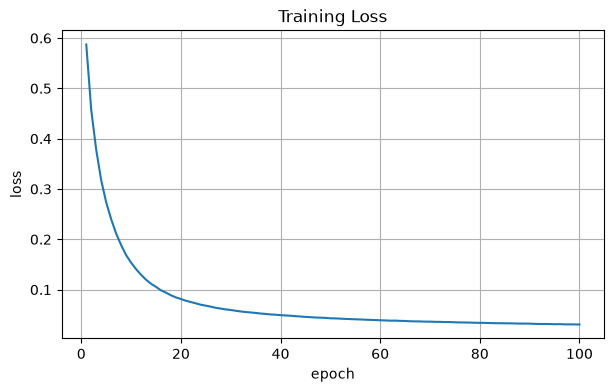

In [30]:
# 학습 곡선
plt.figure(figsize= (7,4))
plt.plot(range(1, EPOCH + 1), loss_history)
plt.xlabel('epoch')
plt.ylabel('loss')
plt.title('Training Loss')
plt.grid()

#### Step 4. 모델 테스트

In [31]:
model.eval()

correct = 0
total = 0
with torch.no_grad():
    for x_batch, y_batch in test_dl:
        y_hat = model(x_batch)
        pred = (y_hat >= 0.5).float()

        correct += (pred == y_batch).sum().item()
        total += y_batch.numel()

accuracy = correct / total * 100
print(f'test accuracy: {correct}/{total} ({accuracy:.1f}%)')

test accuracy: 269/275 (97.8%)


#### Step 5. 테스트 결과 시각화

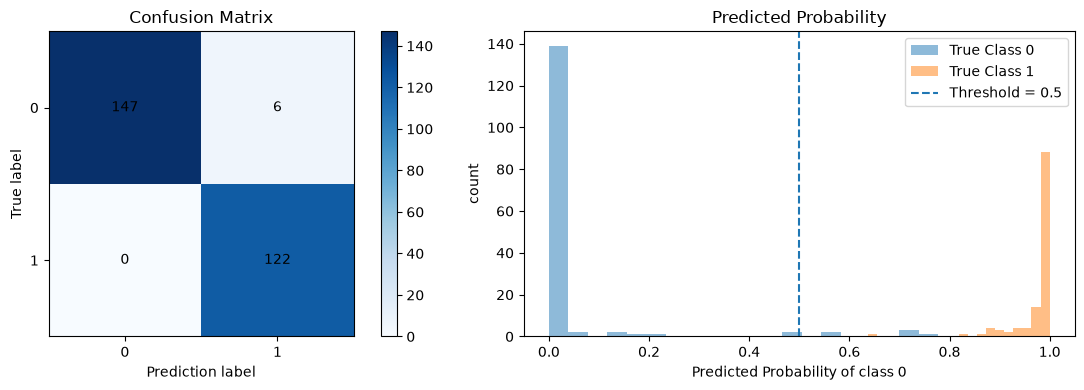

In [32]:
# 혼동행렬 생성 : 행은 실제 클래스, 열은 예측 클래스
model.eval()

y_true_all = [] # 정답 전체를 넣을 리스트 생성
y_prob_all = [] # 예측값 전체를 넣을 리스트 생성

with torch.no_grad():
    for x_batch, y_batch in test_dl:
        y_hat = model(x_batch)

        y_true_all.append(y_batch.numpy().reshape(-1))  # 행의 데이터만 1차원으로 append
        y_prob_all.append(y_hat.numpy().reshape(-1))

# 배치 별로 나누어 저장했던 실제 정답 배열들을 하나로 합친 다음,
# dtype= int 로 데이터 타입을 정수형으로 변환
y_true = np.concatenate(y_true_all).astype(int)     # 정답은 원래 int형이지만 공식처럼 입력
y_prob = np.concatenate(y_prob_all)
y_pred = (y_prob >= 0.5).astype(int)

# 혼동행렬 정의
cm = np.zeros((2,2), dtype=int)
for true, pred in zip(y_true, y_pred):
    cm[true, pred] += 1

fig, axes = plt.subplots(1,2, figsize=(12,4))

im = axes[0].imshow(cm, cmap='Blues')                   # 표 생성
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Prediction label')
axes[0].set_ylabel('True label')
axes[0].set_xticks([0,1], labels=['0','1'])
axes[0].set_yticks([0,1], labels=['0','1'])

for i in range(2) :
    for j in range(2) :
        axes[0].text(j, i, cm[i,j], ha='center', va='center')

fig.colorbar(im, ax=axes[0])

# 클래스별 예측 확률 분포
axes[1].hist(y_prob[y_true == 0], bins=20, alpha= 0.5, label= 'True Class 0')
axes[1].hist(y_prob[y_true == 1], bins=20, alpha= 0.5, label= 'True Class 1')
axes[1].axvline(0.5, linestyle= '--', label= 'Threshold = 0.5')
axes[1].set_title('Predicted Probability')
axes[1].set_xlabel('Predicted Probability of class 0')
axes[1].set_ylabel('count')
axes[1].legend()
plt.tight_layout()

plt.show()